# Churn model comparison

Saved outputs show the original full experiment. The default execution mode is a small smoke check, not a reproduction of those scores.

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data/processed/cleaned_train.csv").is_file():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "results/rerun"
OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = True  # Small execution check. Set False explicitly for the historical search.


In [80]:
import pandas as pd

df_train = pd.read_csv(ROOT / 'data/processed/cleaned_train.csv')
df_test = pd.read_csv(ROOT / 'data/processed/cleaned_test.csv')


In [81]:
#calculate baselines for the confusion matrix and precision
def calculate_baselines(y_true):
    from collections import Counter
    import numpy as np

    counter = Counter(y_true)
    most_common_class, most_common_count = counter.most_common(1)[0]
    total_count = len(y_true)

    baseline_accuracy = most_common_count / total_count
   

    return baseline_accuracy
y_true = df_train['Churn']  
baseline_accuracy = calculate_baselines(y_true)
print(f'Baseline Accuracy: {baseline_accuracy:.2f}')


Baseline Accuracy: 0.85


In [82]:
# log reg on churn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate

import numpy as np
import importlib
import evaluation as utils


import matplotlib.pyplot as plt
import numpy as np
X_train = df_train.drop(columns=['Churn'])
y_train = df_train['Churn']
X_test = df_test.drop(columns=['Churn'])
y_test = df_test['Churn']
# save models in 
models = []

if SMOKE_TEST:
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=128, stratify=y_train, random_state=42)
    X_test, _, y_test, _ = train_test_split(X_test, y_test, train_size=64, stratify=y_test, random_state=42)

# Preserve original grids when SMOKE_TEST=False; use one candidate and two folds for checks.
ResearchGridSearchCV = GridSearchCV
def GridSearchCV(estimator, param_grid, cv, scoring):
    if SMOKE_TEST:
        param_grid = {key: [values[0]] for key, values in param_grid.items()}
        cv = KFold(n_splits=2, shuffle=True, random_state=42)
    return ResearchGridSearchCV(estimator, param_grid=param_grid, cv=cv, scoring=scoring)



Logistic Regression


Logistic Regression - Training accuracy: 86.20%
Logistic Regression - Test accuracy: 85.31%
[[552  20]
 [ 78  17]]


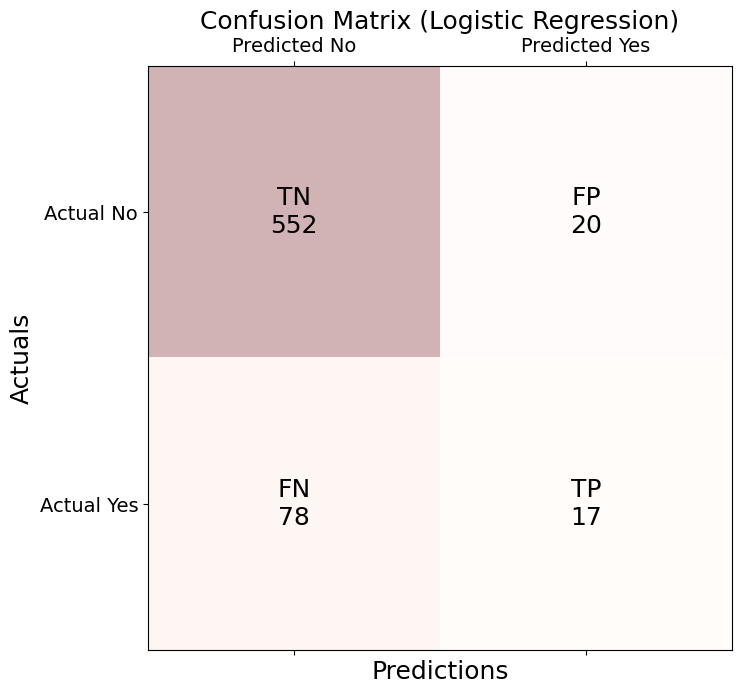

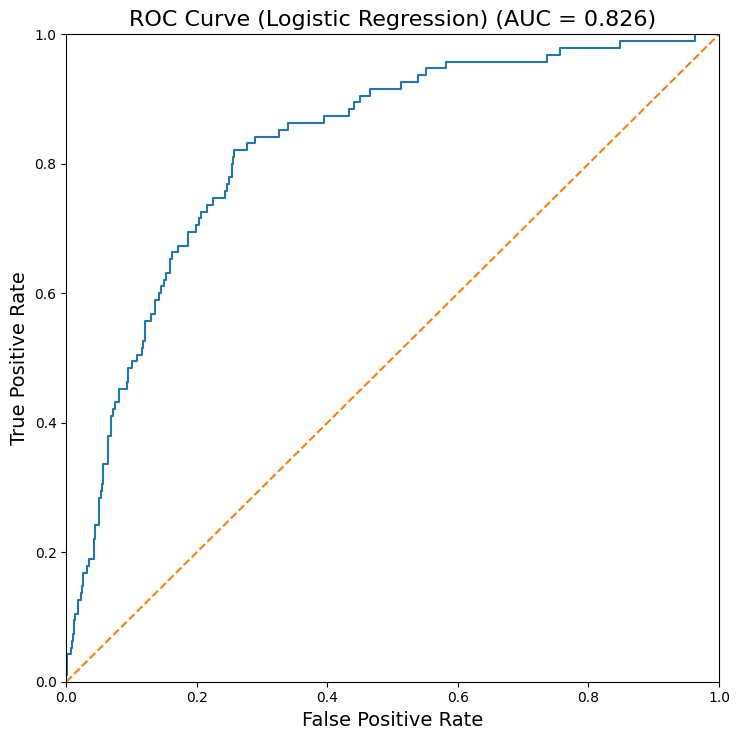

Logistic Regression - AUC: 0.826


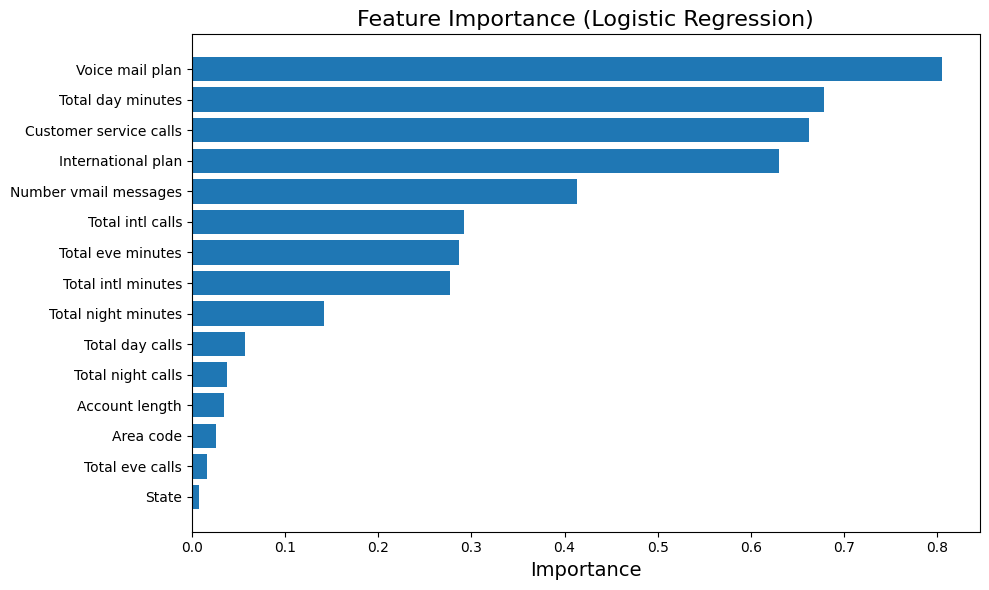

In [83]:
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
# Predict on training data
models.append(utils.evaluate_model(model, "Logistic Regression", X_train, y_train, X_test, y_test))


Best hyperparameters for Decision Tree: {'max_depth': None, 'min_samples_split': 10}
DecisionTreeClassifier - Training accuracy: 97.60%
DecisionTreeClassifier - Test accuracy: 93.25%
[[553  19]
 [ 26  69]]


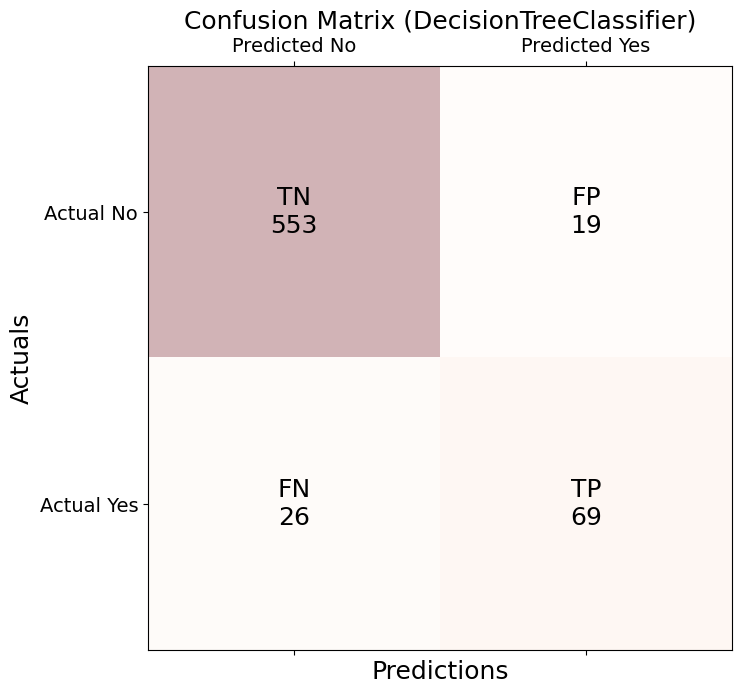

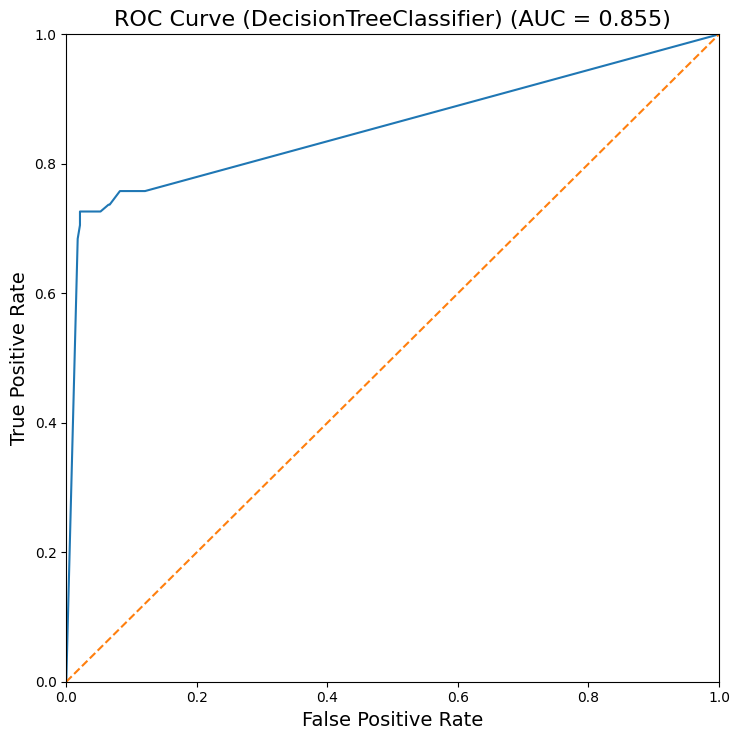

DecisionTreeClassifier - AUC: 0.855


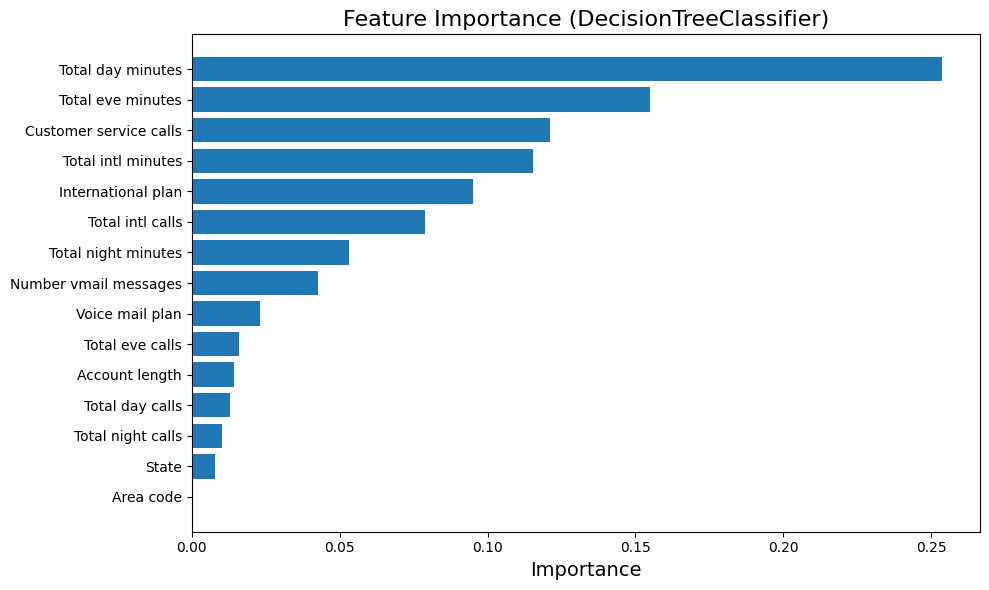

In [84]:
# do decision tree on churn
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(random_state=42)

cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'max_depth': [None, 10, 20, 30], 'min_samples_split': [2, 5, 10]}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best hyperparameters for Decision Tree:", grid.best_params_)
# Predict on training data
models.append(utils.evaluate_model(best_model, "DecisionTreeClassifier", X_train, y_train, X_test, y_test))


Best hyperparameters for Random Forest: {'max_depth': 10, 'n_estimators': 50}
RandomForestClassifier - Training accuracy: 97.75%
RandomForestClassifier - Test accuracy: 93.85%
[[570   2]
 [ 39  56]]


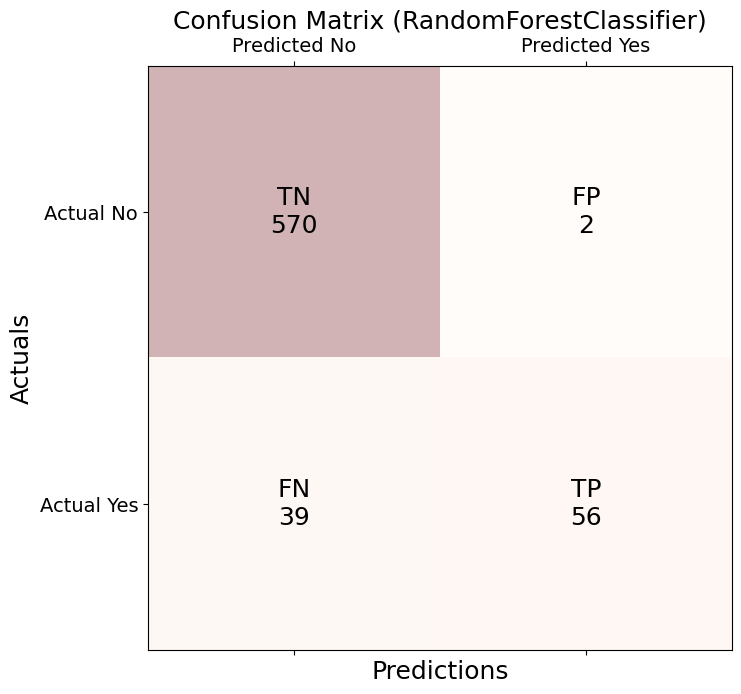

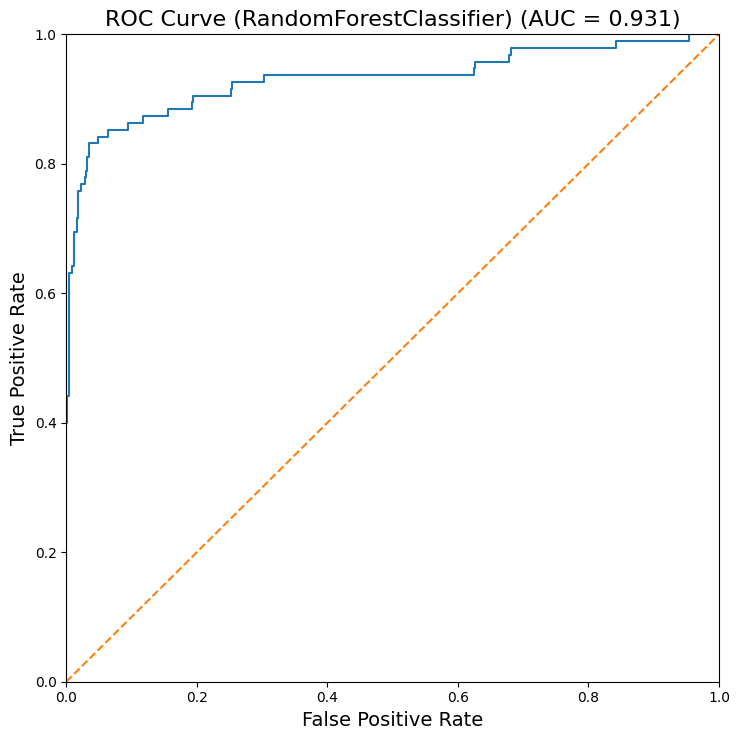

RandomForestClassifier - AUC: 0.931


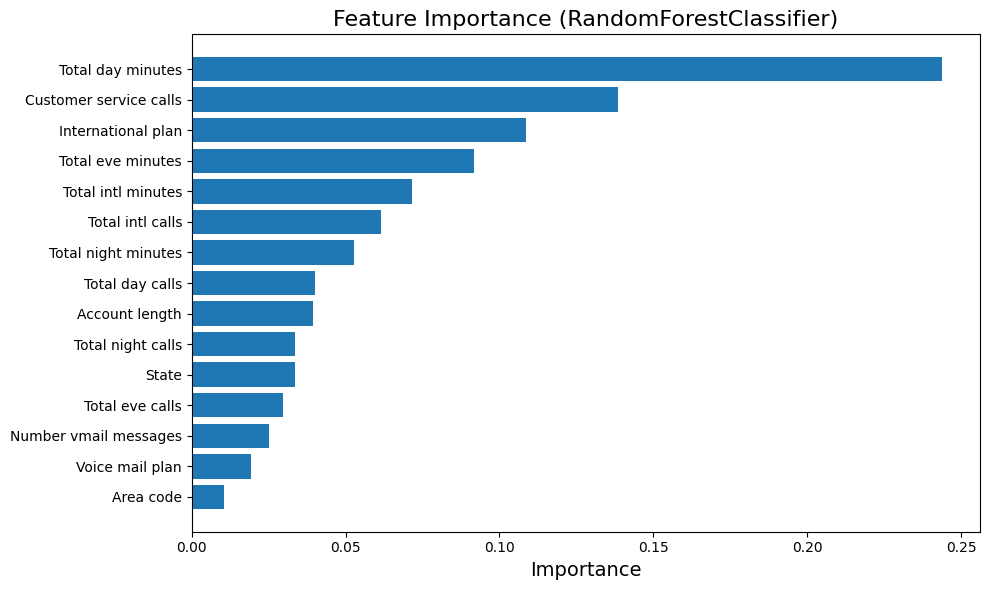

In [85]:
#random forest on churn
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)

cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'n_estimators': [10, 50, 100], 'max_depth': [None, 10, 20, 30]}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best hyperparameters for Random Forest:", grid.best_params_)
# Predict on training data
models.append(utils.evaluate_model(best_model, "RandomForestClassifier", X_train, y_train, X_test, y_test))


Best hyperparameters for SVM: {'C': 1, 'kernel': 'rbf'}
SVM - Training accuracy: 94.11%
SVM - Test accuracy: 91.60%
[[565   7]
 [ 49  46]]


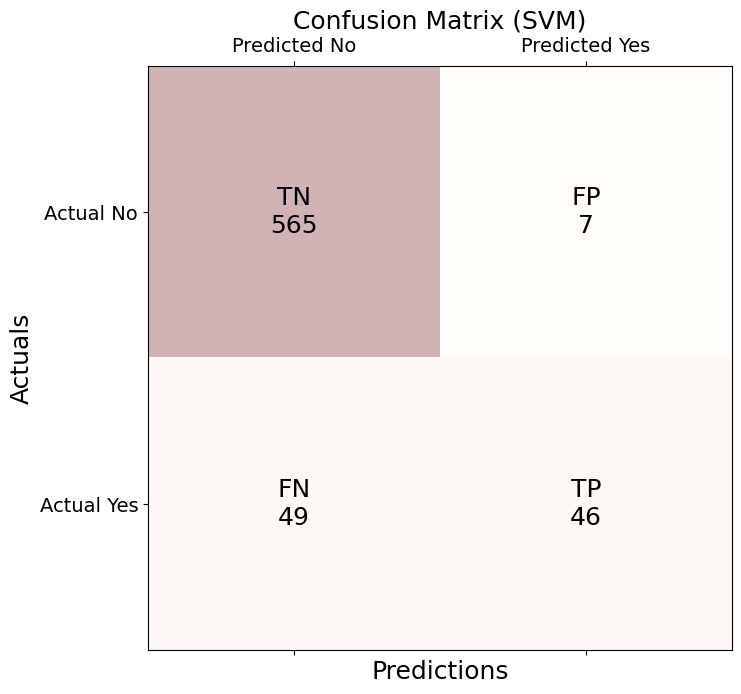

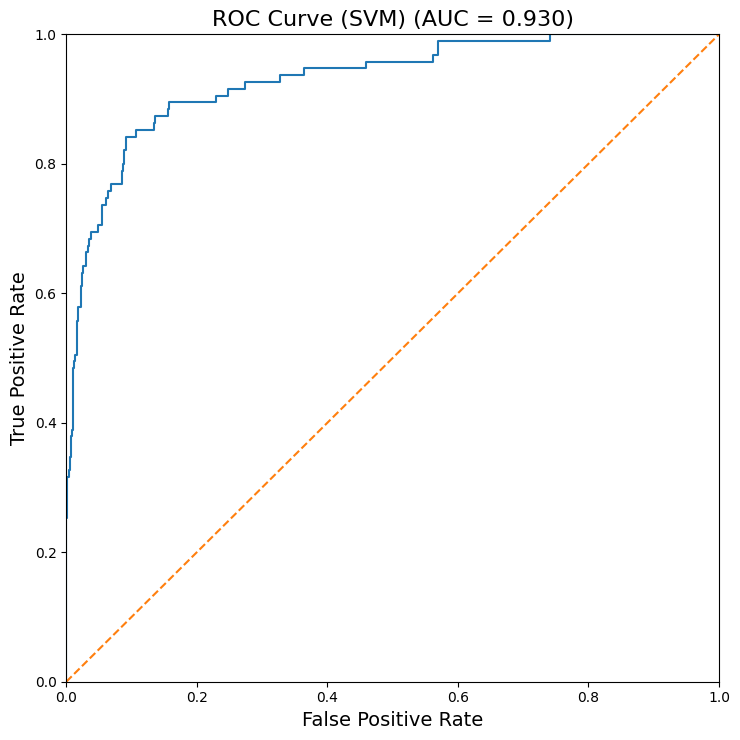

SVM - AUC: 0.930
SVM - Feature importance skipped: This model has neither feature_importances_ nor coef_. Use permutation importance (model-agnostic) or SHAP.


In [86]:
#SVM on churn
from sklearn.svm import SVC

model = SVC(random_state=42, probability=True)

cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_
#print best hyperparameters
print("Best hyperparameters for SVM:", grid.best_params_)
# Predict on training data
models.append(utils.evaluate_model(best_model, "SVM", X_train, y_train, X_test, y_test))


Best hyperparameters for KNN: {'n_neighbors': 11}
K-Nearest Neighbors - Training accuracy: 88.71%
K-Nearest Neighbors - Test accuracy: 87.26%
[[567   5]
 [ 80  15]]


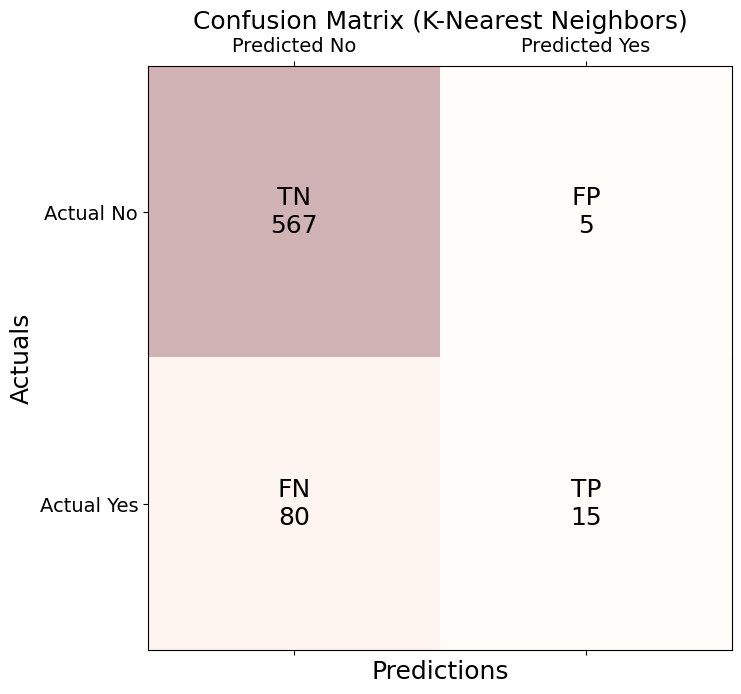

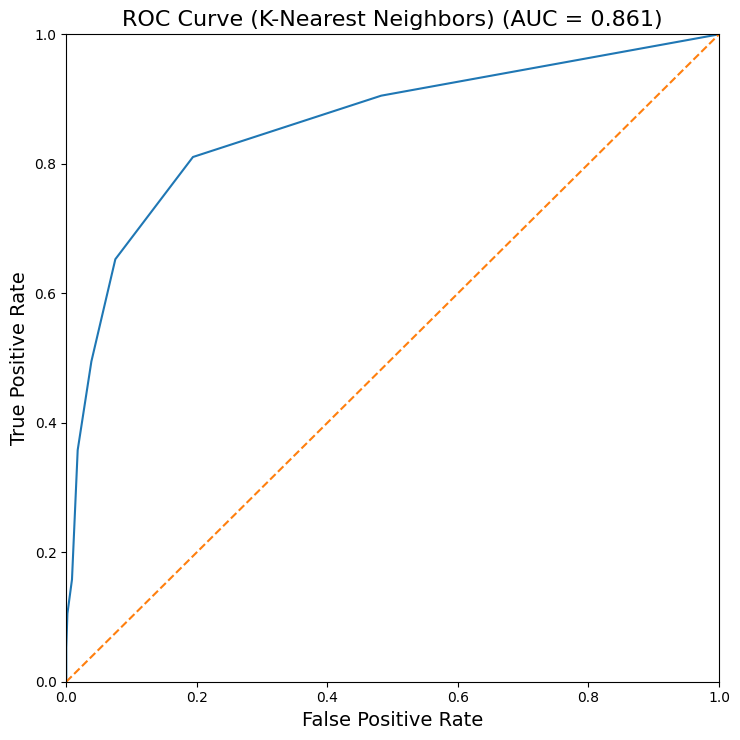

K-Nearest Neighbors - AUC: 0.861
K-Nearest Neighbors - Feature importance skipped: This model has neither feature_importances_ nor coef_. Use permutation importance (model-agnostic) or SHAP.


In [87]:
#KNN on churn
from sklearn.neighbors import KNeighborsClassifier


model = KNeighborsClassifier()
# do a grid search of the K papameter 
cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'n_neighbors': [3, 5, 7, 9, 11]}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)



grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("Best hyperparameters for KNN:", grid.best_params_)
# Predict on training data
models.append(utils.evaluate_model(best_model, "K-Nearest Neighbors", X_train, y_train, X_test, y_test))


Best hyperparameters for RidgeClassifier: {'alpha': 0.1}
RidgeClassifier - Training accuracy: 86.12%
RidgeClassifier - Test accuracy: 85.61%
[[563   9]
 [ 87   8]]


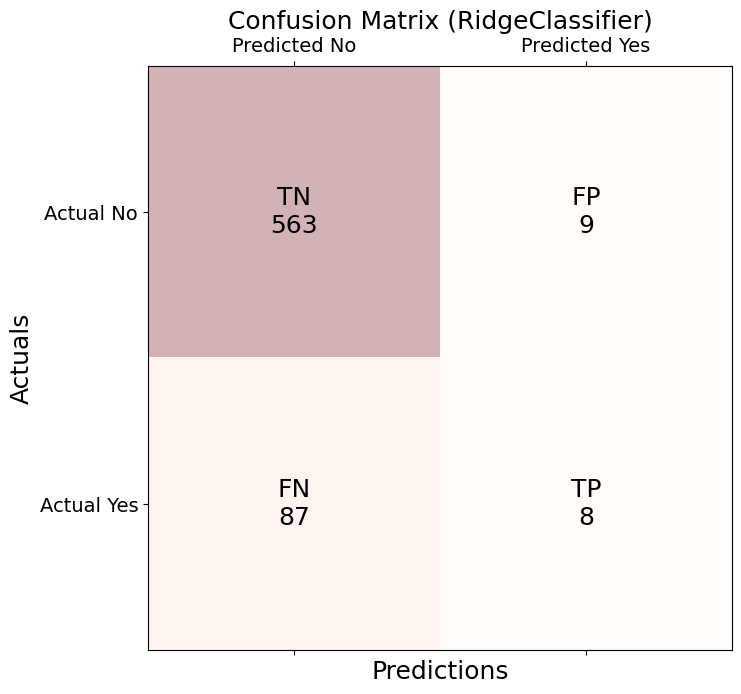

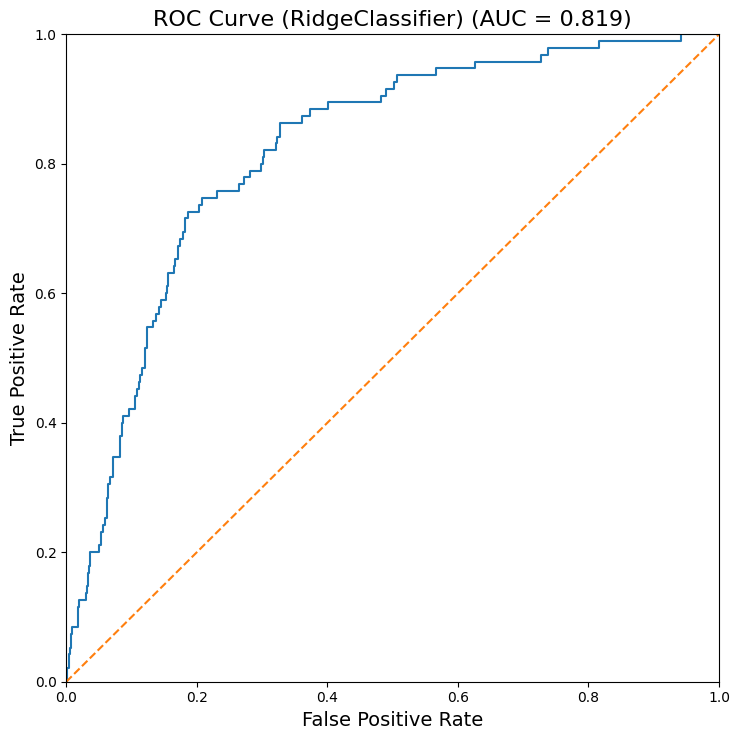

RidgeClassifier - AUC: 0.819


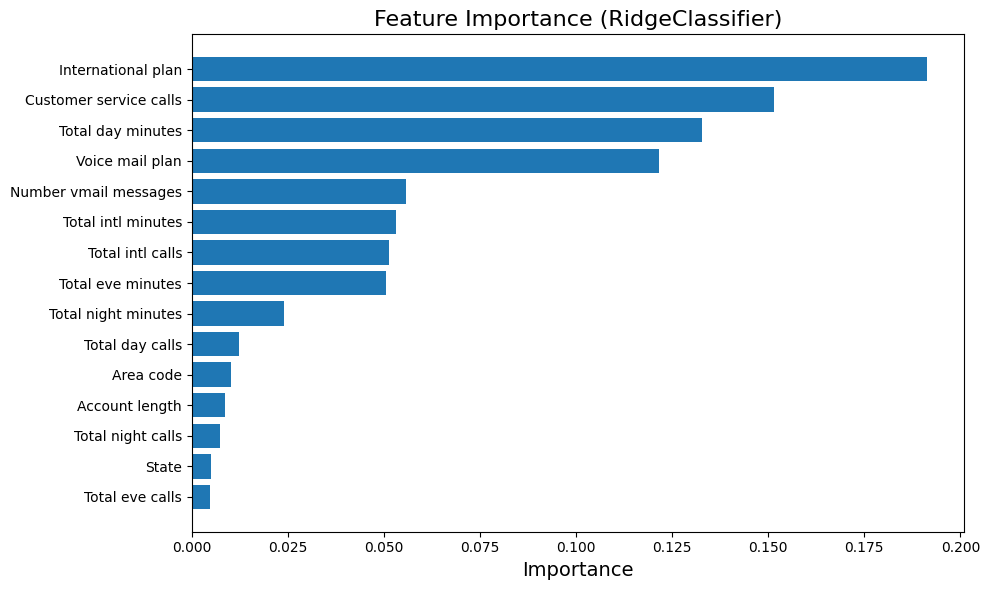

In [88]:
#KNN on churn
from sklearn.linear_model import RidgeClassifier


model = RidgeClassifier()
# do a grid search of the K papameter 
cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'alpha': [0.1, 1.0, 10.0]}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)



grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best hyperparameters for RidgeClassifier:", grid.best_params_)
# Predict on training data
models.append(utils.evaluate_model(best_model, "RidgeClassifier", X_train, y_train, X_test, y_test))


Best parameters: {'n_estimators': 54}
BaggingClassifier - Training accuracy: 99.96%
BaggingClassifier - Test accuracy: 95.80%
[[567   5]
 [ 23  72]]


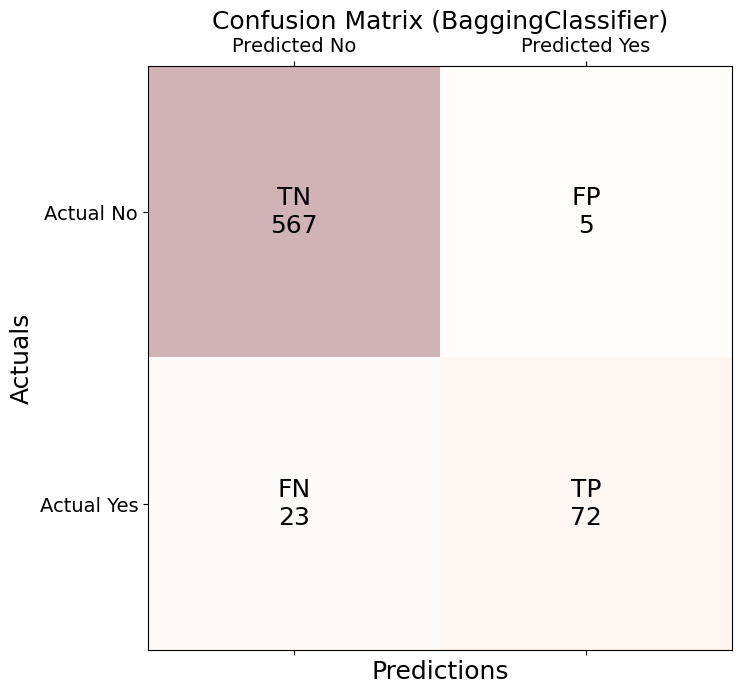

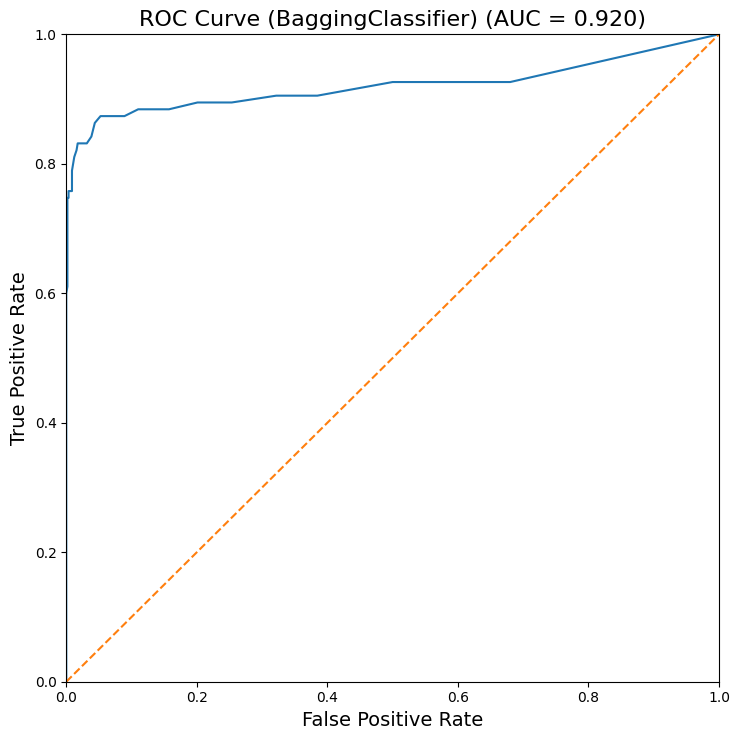

BaggingClassifier - AUC: 0.920
BaggingClassifier - Feature importance skipped: This model has neither feature_importances_ nor coef_. Use permutation importance (model-agnostic) or SHAP.


In [89]:
#bagging on churn
from sklearn.ensemble import BaggingClassifier
model = BaggingClassifier(random_state=42)
cv = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'n_estimators': [57, 60, 54]}
grid = GridSearchCV(
    model, param_grid = param_grid, cv=cv, scoring="roc_auc"
)



grid.fit(X_train, y_train)
best_model = grid.best_estimator_
#print best n_estimators
print("Best parameters:", grid.best_params_)

# Predict on training data
models.append(utils.evaluate_model(best_model, "BaggingClassifier", X_train, y_train, X_test, y_test))


In [91]:
models_df = pd.DataFrame(models)

models_df[['model', 'accuracy_train', 'accuracy_test', 'auc']]
#export to csv
models_df.to_csv(OUTPUT / ('model_evaluation_smoke.csv' if SMOKE_TEST else 'model_evaluation.csv'), index=False)
